# Projet Machine Learning 2026

**Nom : Ellaoui Abdelhamid**  
**Niveau : IDSA**

Notebook structuré avec une cellule Markdown explicative et une cellule Code pour chaque étape.


## Étape 0 – Importation des bibliothèques

Import des bibliothèques de manipulation de données (pandas, numpy), de visualisation (matplotlib, seaborn) et de modélisation (scikit-learn). Création des dossiers `images/` et `results/` où sont sauvegardés automatiquement les graphes et tableaux utilisés dans le README.

In [1]:
# =====================================================
# ETAPE 0 : IMPORTATION DES BIBLIOTHEQUES
# Auteur : Ellaoui Abdelhamid - IDSA
# =====================================================

import os
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR, SVC

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.metrics import f1_score

os.makedirs('images',exist_ok=True)
os.makedirs('results',exist_ok=True)
res_reg={}
res_clf={}

## Étape 1 – Chargement des données

Chargement du fichier `ndvi.xlsx` (série temporelle de végétation et variables climatiques) et conversion de la colonne `date` au format datetime, indispensable pour toute analyse temporelle.

In [2]:

df = pd.read_excel('ndvi.xlsx')
df['date'] = pd.to_datetime(df['date'])
print(df.head())


        date  ndvi_moyen  ndvi_min  ndvi_max  ndvi_ecart  pluviometrie  \
0 2017-01-01    0.050000  0.000000  0.157161    0.039290     14.718217   
1 2017-01-09         NaN  0.000000  0.127998    0.031999           NaN   
2 2017-01-17    0.096329  0.000000  0.223278    0.055820     39.355062   
3 2017-01-25    0.177806  0.047122  0.246510    0.049847     48.958610   
4 2017-02-02    0.131412  0.000000  0.213780    0.053445     13.397247   

   temperature  humidite_sol  ndvi_futur           etat  
0    13.162608     32.956409    0.096329  Stress severe  
1    16.098771     45.909513    0.177806  Stress severe  
2    18.561200     46.222068    0.131412  Stress severe  
3    18.255973     44.298397    0.175849  Stress severe  
4    18.536902     33.116775    0.313081  Stress severe  


## Étape 2 – Informations générales

Aperçu de la structure du jeu de données : types, nombre de lignes, valeurs non nulles et statistiques descriptives. Le tableau est sauvegardé dans `results/`.

In [3]:
print(df.info())
display(df.describe(include='all'))

df.describe(include='all').T.round(3).to_csv('results/statistiques_descriptives.csv')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          300 non-null    datetime64[ns]
 1   ndvi_moyen    270 non-null    float64       
 2   ndvi_min      300 non-null    float64       
 3   ndvi_max      300 non-null    float64       
 4   ndvi_ecart    300 non-null    float64       
 5   pluviometrie  272 non-null    float64       
 6   temperature   271 non-null    float64       
 7   humidite_sol  270 non-null    float64       
 8   ndvi_futur    298 non-null    float64       
 9   etat          300 non-null    object        
dtypes: datetime64[ns](1), float64(8), object(1)
memory usage: 23.6+ KB
None


,date,ndvi_moyen,ndvi_min,ndvi_max,ndvi_ecart,pluviometrie,temperature,humidite_sol,ndvi_futur,etat
count,300,270.000000,300.000000,300.000000,300.000000,272.000000,271.000000,270.000000,298.000000,300
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Stress severe
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,119
mean,2020-04-11 00:00:00,0.325703,0.241267,0.425469,0.046051,34.682047,18.820639,40.265702,0.329540,NaN
min,2017-01-01 00:00:00,-1.200000,0.000000,0.100463,0.025116,-5.000000,-30.000000,23.188832,0.050000,NaN
25%,2018-08-22 00:00:00,0.059259,0.000000,0.183778,0.037796,15.678570,12.137464,34.343479,0.064344,NaN
50%,2020-04-11 00:00:00,0.326529,0.238053,0.418220,0.045196,27.270231,19.000397,39.204458,0.326529,NaN
75%,2021-11-30 00:00:00,0.571735,0.454424,0.652066,0.052803,41.374026,25.507072,45.179733,0.560817,NaN
max,2023-07-21 00:00:00,2.000000,0.674445,0.886566,0.072718,350.000000,80.000000,62.750282,0.744316,NaN


## Étape 3 – Série temporelle NDVI

Visualisation de l'évolution temporelle du NDVI moyen pour repérer tendance, saisonnalité et anomalies.

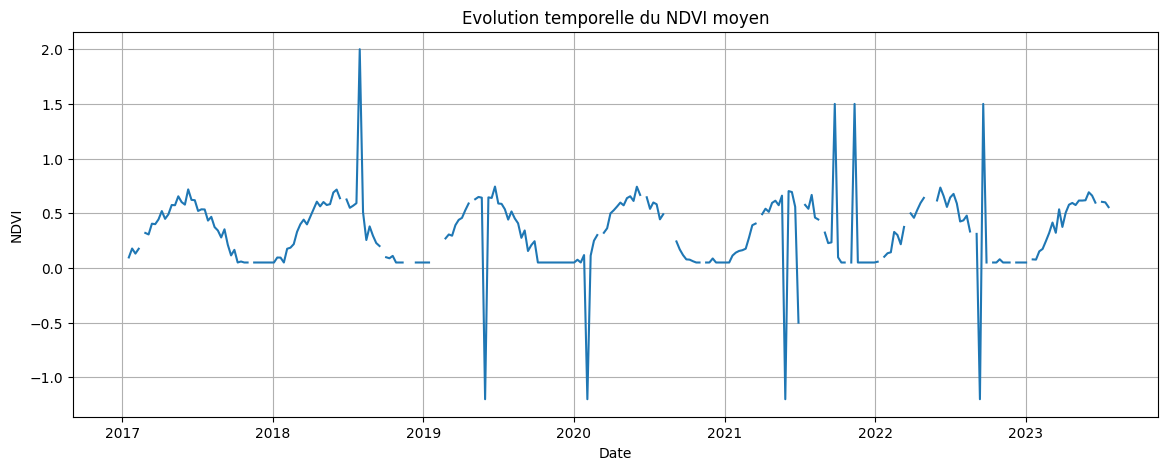

In [4]:
plt.figure(figsize=(14,5))
plt.plot(df['date'],df['ndvi_moyen'])
plt.title('Evolution temporelle du NDVI moyen')
plt.xlabel('Date')
plt.ylabel('NDVI')
plt.grid()
plt.savefig('images/01_serie_temporelle_ndvi.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 4 – Corrélations

Matrice de corrélation entre variables numériques pour identifier les relations NDVI / climat et les variables redondantes.

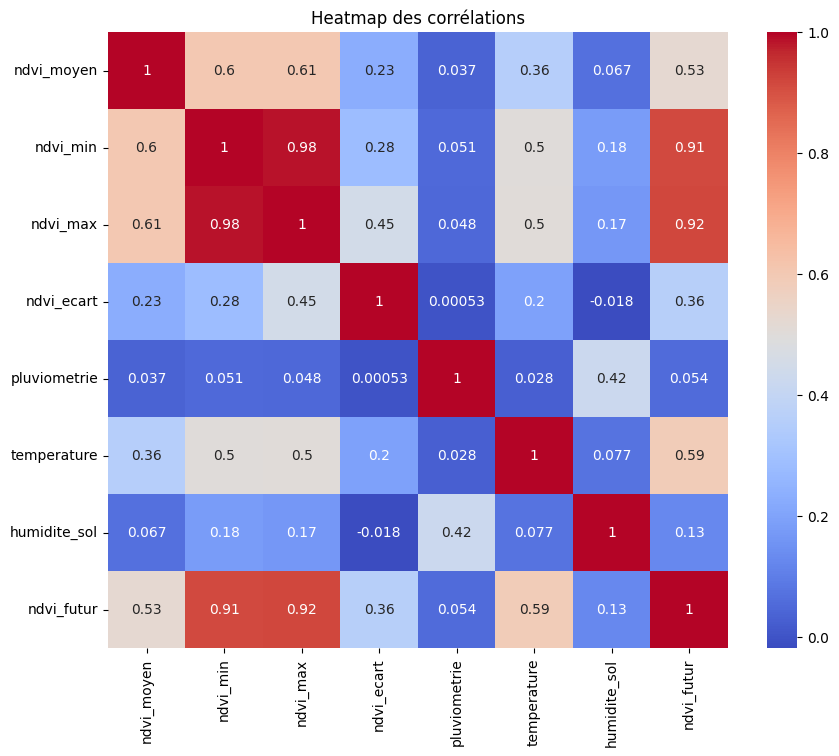

In [5]:
num=df.select_dtypes(include=np.number)
plt.figure(figsize=(10,8))
sns.heatmap(num.corr(),annot=True,cmap='coolwarm')
plt.title('Heatmap des corrélations')
plt.savefig('images/02_heatmap_correlations.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 5 – Valeurs manquantes

Comptage et visualisation des valeurs manquantes par variable avant nettoyage.

date             0
ndvi_moyen      30
ndvi_min         0
ndvi_max         0
ndvi_ecart       0
pluviometrie    28
temperature     29
humidite_sol    30
ndvi_futur       2
etat             0
dtype: int64


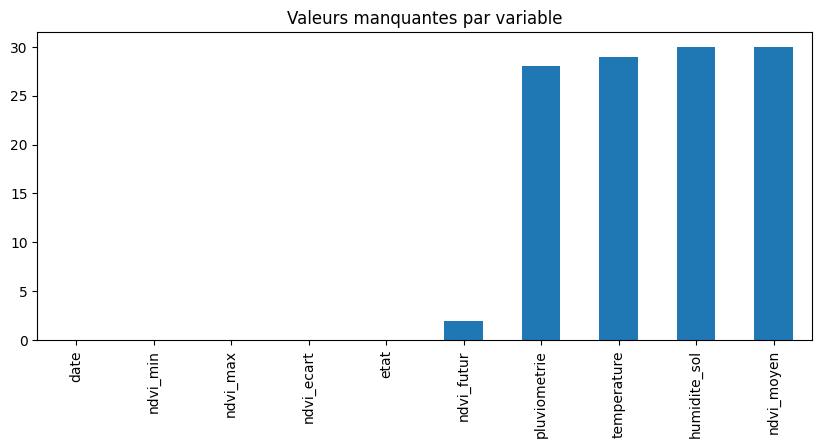

In [6]:
na=df.isnull().sum()
print(na)

plt.figure(figsize=(10,4))
na.sort_values().plot(kind='bar')
plt.title('Valeurs manquantes par variable')
plt.savefig('images/03_valeurs_manquantes.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 6 – Valeurs aberrantes

Détection des valeurs aberrantes à l'aide de règles physiques (NDVI ∈ [0,1], pluviométrie ∈ [0,200], température ∈ [-5,55], humidité du sol ∈ [0,100]). Les valeurs hors bornes sont remplacées par NaN. Boxplots avant/après correction.

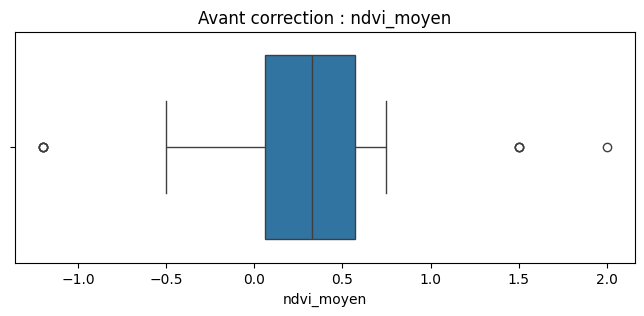

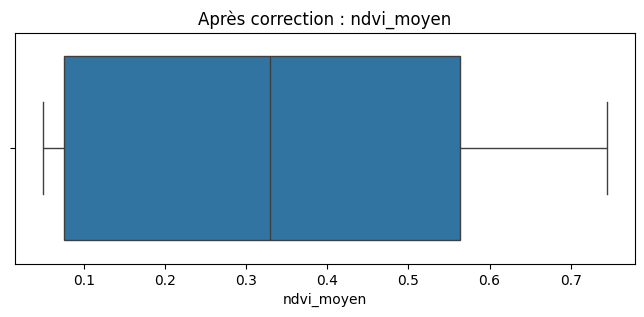

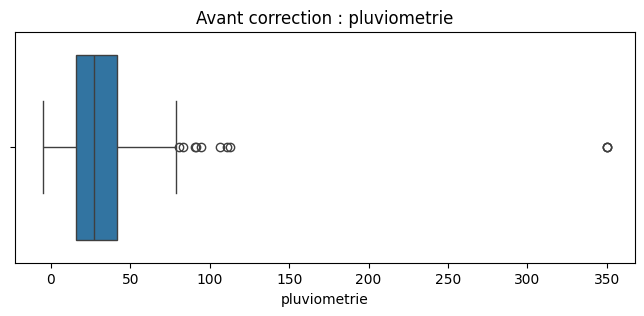

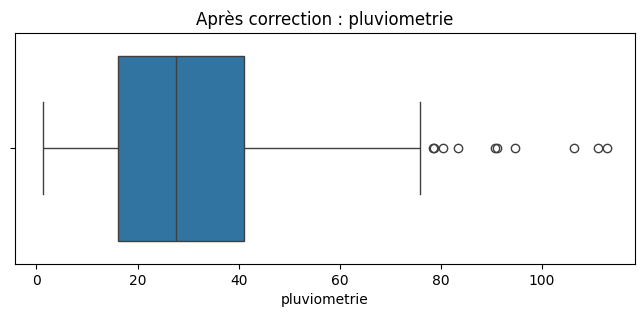

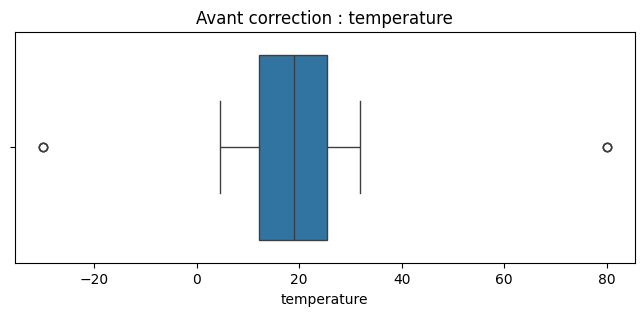

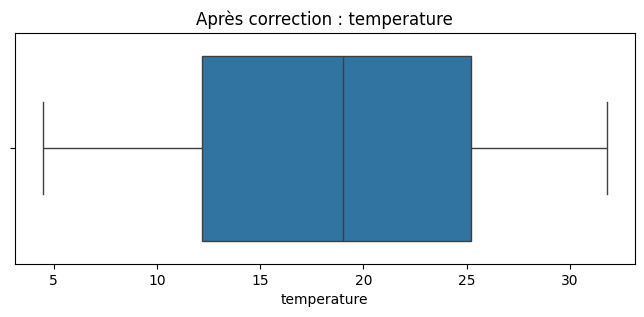

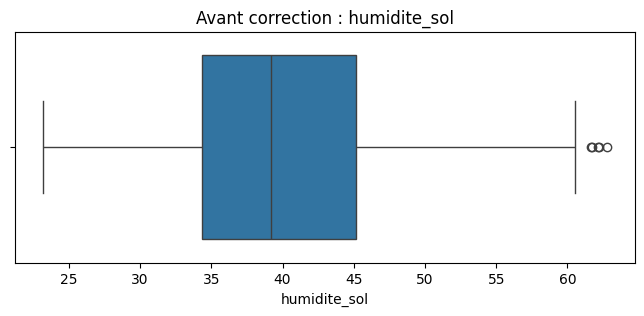

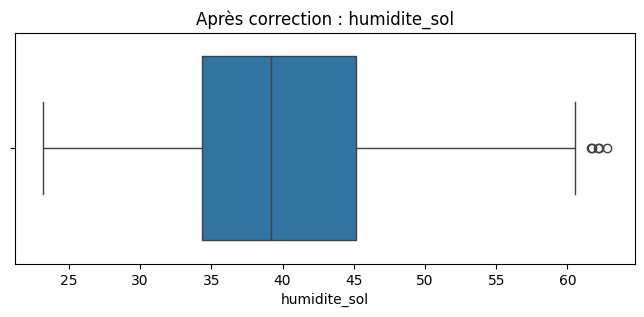

In [7]:
regles={
'ndvi_moyen':(0,1),
'pluviometrie':(0,200),
'temperature':(-5,55),
'humidite_sol':(0,100)
}

for col,(mini,maxi) in regles.items():
    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[col])
    plt.title(f'Avant correction : {col}')
    plt.savefig(f'images/04_boxplot_avant_{col}.png',dpi=150,bbox_inches='tight')
    plt.show()

    df.loc[(df[col]<mini)|(df[col]>maxi),col]=np.nan

    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[col])
    plt.title(f'Après correction : {col}')
    plt.savefig(f'images/05_boxplot_apres_{col}.png',dpi=150,bbox_inches='tight')
    plt.show()

## Étape 7 – Imputation

Imputation : interpolation pour les variables continues dans le temps (NDVI, température), moyenne pour l'humidité du sol, médiane pour la pluviométrie (distribution asymétrique).

In [8]:
df['ndvi_moyen']=df['ndvi_moyen'].interpolate()
df['temperature']=df['temperature'].interpolate()

df['humidite_sol']=df['humidite_sol'].fillna(df['humidite_sol'].mean())
df['pluviometrie']=df['pluviometrie'].fillna(df['pluviometrie'].median())

print(df.isnull().sum())

date            0
ndvi_moyen      0
ndvi_min        0
ndvi_max        0
ndvi_ecart      0
pluviometrie    0
temperature     0
humidite_sol    0
ndvi_futur      2
etat            0
dtype: int64


## Étape 8 – Feature Engineering

Création de variables dérivées : mois, jour de l'année (saisonnalité), retards du NDVI (lag 1 et 2), moyenne glissante sur 3 pas et variation (delta) du NDVI. Les lignes incomplètes générées par les décalages sont supprimées.

In [9]:

df['mois']=df['date'].dt.month
df['jour_annee']=df['date'].dt.dayofyear
df['ndvi_lag1']=df['ndvi_moyen'].shift(1)
df['ndvi_lag2']=df['ndvi_moyen'].shift(2)
df['ndvi_roll3']=df['ndvi_moyen'].rolling(3).mean()
df['delta_ndvi']=df['ndvi_moyen'].diff()

df_ml=df.dropna().copy()
display(df_ml.head())


,date,ndvi_moyen,ndvi_min,ndvi_max,ndvi_ecart,pluviometrie,temperature,humidite_sol,ndvi_futur,etat,mois,jour_annee,ndvi_lag1,ndvi_lag2,ndvi_roll3,delta_ndvi
2,2017-01-17,0.096329,0.000000,0.223278,0.055820,39.355062,18.561200,46.222068,0.131412,Stress severe,1,17,0.073165,0.050000,0.073165,0.023165
3,2017-01-25,0.177806,0.047122,0.246510,0.049847,48.958610,18.255973,44.298397,0.175849,Stress severe,1,25,0.096329,0.073165,0.115767,0.081477
4,2017-02-02,0.131412,0.000000,0.213780,0.053445,13.397247,18.536902,33.116775,0.313081,Stress severe,2,33,0.177806,0.096329,0.135182,-0.046394
5,2017-02-10,0.175849,0.084587,0.268392,0.045951,20.506624,17.258595,52.117525,0.320305,Stress severe,2,41,0.131412,0.177806,0.161689,0.044437
6,2017-02-18,0.248077,0.225879,0.413842,0.046991,23.586127,19.082469,38.569603,0.306614,Stress modere,2,49,0.175849,0.131412,0.185113,0.072228


## Étape 9 – Préparation régression

Définition des variables explicatives et de la cible de régression `ndvi_futur`. Découpage **chronologique** 80 % entraînement / 20 % test (sans mélange) pour respecter la nature temporelle des données.

In [10]:

features=['ndvi_moyen','ndvi_min','ndvi_max','ndvi_ecart',
'pluviometrie','temperature','humidite_sol',
'mois','jour_annee','ndvi_lag1','ndvi_lag2',
'ndvi_roll3','delta_ndvi']

X=df_ml[features]
y=df_ml['ndvi_futur']

split=int(len(df_ml)*0.8)

X_train=X.iloc[:split]
X_test=X.iloc[split:]
y_train=y.iloc[:split]
y_test=y.iloc[split:]


## Étape 10 – Linear Regression

Modèle de référence (baseline) : régression linéaire avec standardisation. Évaluation par R², RMSE et MAE + graphe réel vs prédit.

R2 = 0.9331121738641631
RMSE = 0.0620845857851934
MAE = 0.0485488093664131


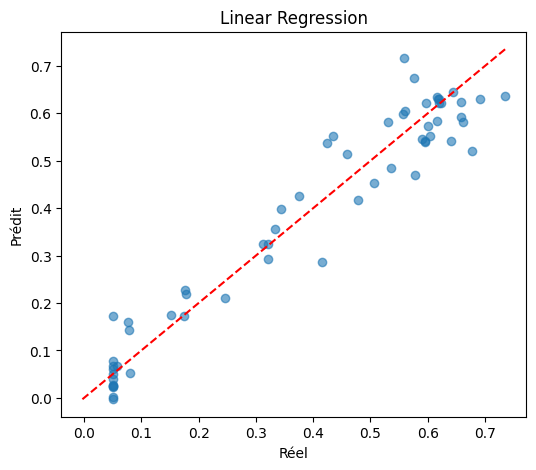

In [11]:
pipe=Pipeline([
('scaler',StandardScaler()),
('model',LinearRegression())
])

pipe.fit(X_train,y_train)
pred=pipe.predict(X_test)

print('R2 =',r2_score(y_test,pred))
print('RMSE =',np.sqrt(mean_squared_error(y_test,pred)))
print('MAE =',mean_absolute_error(y_test,pred))

res_reg['Linear Regression']=(r2_score(y_test,pred),np.sqrt(mean_squared_error(y_test,pred)),mean_absolute_error(y_test,pred))

plt.figure(figsize=(6,5))
plt.scatter(y_test,pred,alpha=0.6)
lim=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]
plt.plot(lim,lim,'r--')
plt.xlabel('Réel')
plt.ylabel('Prédit')
plt.title('Linear Regression')
plt.savefig('images/06_linear_regression_reel_vs_predit.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 11 – Random Forest Regressor

Random Forest Regressor : modèle d'ensemble capable de capturer des relations non linéaires. Mêmes métriques que la baseline.

R2 = 0.966451159271094
RMSE = 0.04396924476913303
MAE = 0.0319457440841046


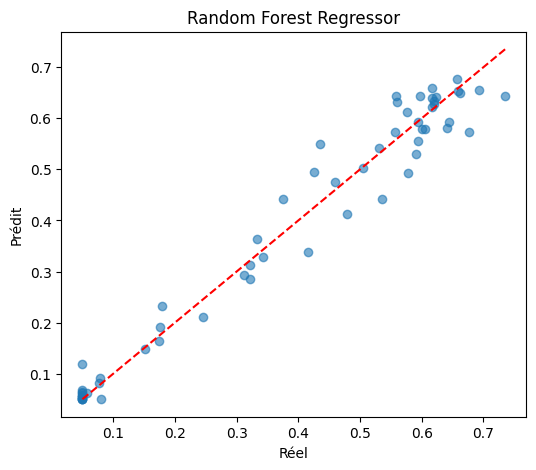

In [12]:
rf=Pipeline([
('scaler',StandardScaler()),
('model',RandomForestRegressor(random_state=42))
])

rf.fit(X_train,y_train)
pred_rf=rf.predict(X_test)

print('R2 =',r2_score(y_test,pred_rf))
print('RMSE =',np.sqrt(mean_squared_error(y_test,pred_rf)))
print('MAE =',mean_absolute_error(y_test,pred_rf))

res_reg['Random Forest']=(r2_score(y_test,pred_rf),np.sqrt(mean_squared_error(y_test,pred_rf)),mean_absolute_error(y_test,pred_rf))

plt.figure(figsize=(6,5))
plt.scatter(y_test,pred_rf,alpha=0.6)
lim=[min(y_test.min(),pred_rf.min()),max(y_test.max(),pred_rf.max())]
plt.plot(lim,lim,'r--')
plt.xlabel('Réel'); plt.ylabel('Prédit'); plt.title('Random Forest Regressor')
plt.savefig('images/07_random_forest_reel_vs_predit.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 12 – SVR

Support Vector Regression (noyau RBF par défaut) avec standardisation. Mêmes métriques.

R2 = 0.9091004295896308
RMSE = 0.07237543092689337
MAE = 0.05965394122948496


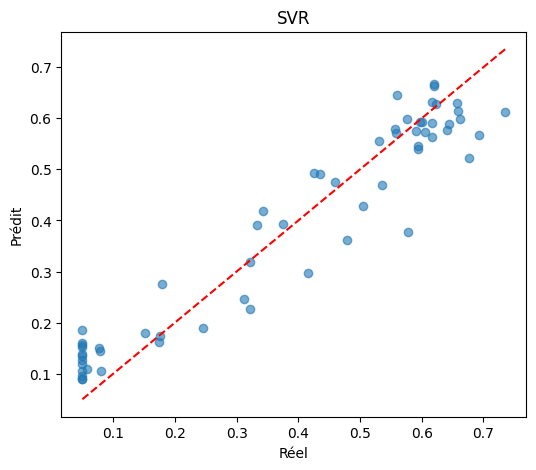

In [13]:
svr=Pipeline([
('scaler',StandardScaler()),
('model',SVR())
])

svr.fit(X_train,y_train)
pred_svr=svr.predict(X_test)

print('R2 =',r2_score(y_test,pred_svr))
print('RMSE =',np.sqrt(mean_squared_error(y_test,pred_svr)))
print('MAE =',mean_absolute_error(y_test,pred_svr))

res_reg['SVR']=(r2_score(y_test,pred_svr),np.sqrt(mean_squared_error(y_test,pred_svr)),mean_absolute_error(y_test,pred_svr))

plt.figure(figsize=(6,5))
plt.scatter(y_test,pred_svr,alpha=0.6)
lim=[min(y_test.min(),pred_svr.min()),max(y_test.max(),pred_svr.max())]
plt.plot(lim,lim,'r--')
plt.xlabel('Réel'); plt.ylabel('Prédit'); plt.title('SVR')
plt.savefig('images/08_svr_reel_vs_predit.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 13 – Validation croisée

Validation croisée adaptée aux séries temporelles (`TimeSeriesSplit`, 5 plis) du Random Forest pour estimer la stabilité de la performance.

[0.91355294 0.94850176 0.96303097 0.94945419 0.96961773]
R2 moyen = 0.948831518642663


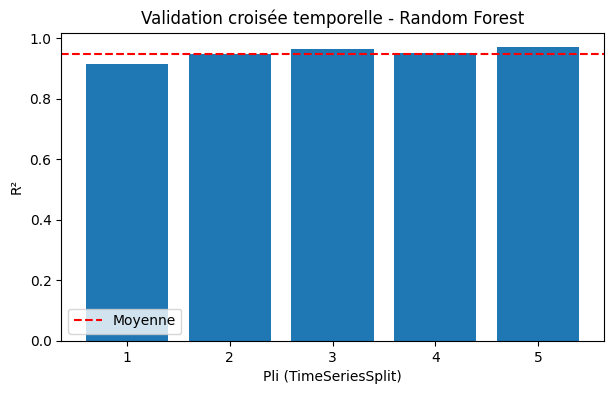

In [14]:
tscv=TimeSeriesSplit(n_splits=5)

scores=cross_val_score(
rf,X,y,cv=tscv,scoring='r2'
)

print(scores)
print('R2 moyen =',scores.mean())

pd.DataFrame({'Pli':range(1,len(scores)+1),'R2':scores.round(4)}).to_csv('results/validation_croisee_rf.csv',index=False)

plt.figure(figsize=(7,4))
plt.bar(range(1,len(scores)+1),scores)
plt.axhline(scores.mean(),color='r',linestyle='--',label='Moyenne')
plt.xlabel('Pli (TimeSeriesSplit)'); plt.ylabel('R²'); plt.title('Validation croisée temporelle - Random Forest'); plt.legend()
plt.savefig('images/09_validation_croisee_rf.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 14 – Préparation classification

Préparation de la classification : cible `etat` (état de la végétation), mêmes variables explicatives et même découpage chronologique.

In [15]:

Xc=df_ml[features]
yc=df_ml['etat']

X_train=Xc.iloc[:split]
X_test=Xc.iloc[split:]
y_train=yc.iloc[:split]
y_test=yc.iloc[split:]


## Étape 15 – Random Forest Classifier

Random Forest Classifier : rapport de classification (précision, rappel, F1) sur le jeu de test.

In [16]:
clf=Pipeline([
('scaler',StandardScaler()),
('model',RandomForestClassifier(random_state=42))
])

clf.fit(X_train,y_train)
pred=clf.predict(X_test)

print(classification_report(y_test,pred))

res_clf['Random Forest']=(accuracy_score(y_test,pred),f1_score(y_test,pred,average='weighted'))

                  precision    recall  f1-score   support

   Stress modere       0.86      0.75      0.80         8
   Stress severe       1.00      0.95      0.97        20
Vegetation dense       0.93      0.93      0.93        15
Vegetation saine       0.84      0.94      0.89        17

        accuracy                           0.92        60
       macro avg       0.91      0.89      0.90        60
    weighted avg       0.92      0.92      0.92        60



## Étape 16 – SVC

SVC (noyau RBF) avec standardisation, pour comparaison avec le Random Forest Classifier.

In [17]:
svc=Pipeline([
('scaler',StandardScaler()),
('model',SVC())
])

svc.fit(X_train,y_train)
pred_svc=svc.predict(X_test)

print(classification_report(y_test,pred_svc))

res_clf['SVC']=(accuracy_score(y_test,pred_svc),f1_score(y_test,pred_svc,average='weighted'))

                  precision    recall  f1-score   support

   Stress modere       0.78      0.88      0.82         8
   Stress severe       1.00      1.00      1.00        20
Vegetation dense       1.00      0.73      0.85        15
Vegetation saine       0.75      0.88      0.81        17

        accuracy                           0.88        60
       macro avg       0.88      0.87      0.87        60
    weighted avg       0.90      0.88      0.88        60



## Étape 17 – Matrice de confusion

Matrice de confusion du Random Forest Classifier pour analyser les erreurs par classe.

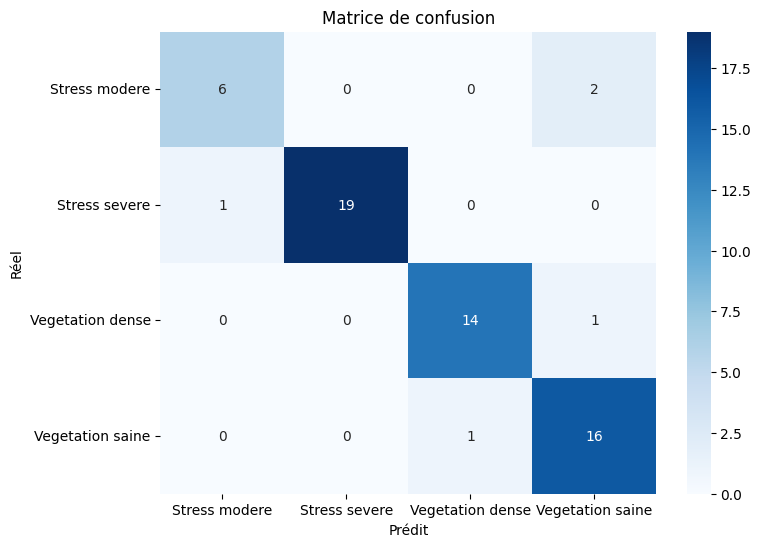

In [18]:
cm=confusion_matrix(y_test,pred)

plt.figure(figsize=(8,6))
labels=sorted(pd.Series(y_test).unique())
sns.heatmap(cm,annot=True,fmt='d',xticklabels=labels,yticklabels=labels,cmap='Blues')
plt.xlabel('Prédit'); plt.ylabel('Réel')
plt.title('Matrice de confusion')
plt.savefig('images/10_matrice_confusion_rf.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 18 – Importance des variables

Importance des variables du Random Forest Classifier pour interpréter les facteurs déterminants.

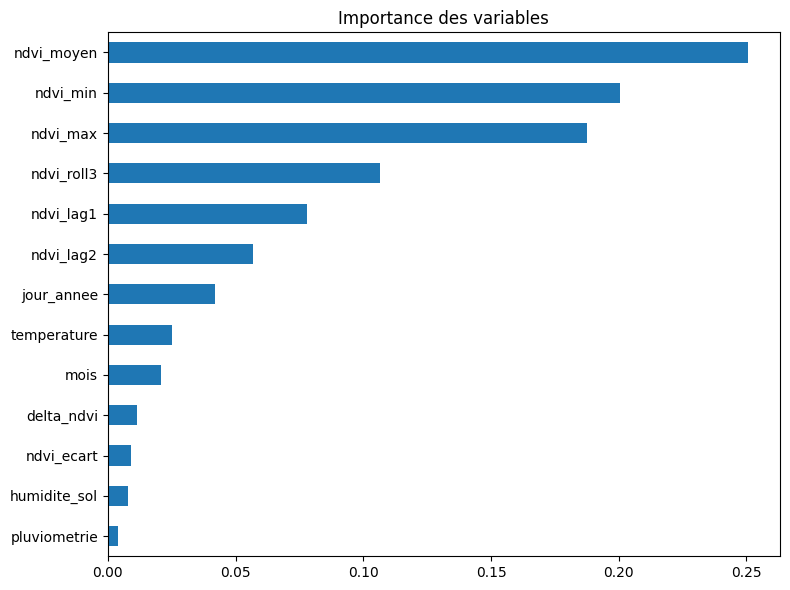

In [19]:
rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(X_train,y_train)

importance=pd.Series(
rf_model.feature_importances_,
index=features
).sort_values()

importance.plot(kind='barh',figsize=(8,6))
plt.title('Importance des variables')
plt.tight_layout()
plt.savefig('images/11_importance_variables.png',dpi=150,bbox_inches='tight')
plt.show()

## Étape 19 – GridSearchCV

Optimisation des hyperparamètres (`n_estimators`, `max_depth`) du Random Forest Regressor par `GridSearchCV` (cv=3, score R²), puis évaluation du meilleur modèle sur le test.

In [20]:
# Cible de régression (y_train/X_train ont été redéfinis pour la classification à l'étape 14)
Xr_train,Xr_test=X.iloc[:split],X.iloc[split:]
yr_train,yr_test=y.iloc[:split],y.iloc[split:]

param_grid={
'n_estimators':[100,200,300],
'max_depth':[5,10,None]
}

grid=GridSearchCV(
RandomForestRegressor(random_state=42),
param_grid,
cv=TimeSeriesSplit(n_splits=3),
scoring='r2'
)

grid.fit(Xr_train,yr_train)

print(grid.best_params_)
print('R2 CV =',grid.best_score_)

pred_grid=grid.best_estimator_.predict(Xr_test)
res_reg['Random Forest (GridSearchCV)']=(r2_score(yr_test,pred_grid),np.sqrt(mean_squared_error(yr_test,pred_grid)),mean_absolute_error(yr_test,pred_grid))
print('Test R2 =',res_reg['Random Forest (GridSearchCV)'][0])
pd.DataFrame([{**grid.best_params_,'R2_CV':round(grid.best_score_,4)}]).to_csv('results/gridsearch_meilleurs_parametres.csv',index=False)

{'max_depth': 5, 'n_estimators': 300}
R2 CV = 0.9375978933780599
Test R2 = 0.9669485030937801


## Étape 20 – Tableau comparatif final

Synthèse : tableaux comparatifs finaux des modèles de régression et de classification, exportés en CSV et Markdown dans `results/`.

,Modèle,R2,RMSE,MAE
0,Linear Regression,0.9331,0.0621,0.0485
1,Random Forest,0.9665,0.0440,0.0319
2,SVR,0.9091,0.0724,0.0597
3,Random Forest (GridSearchCV),0.9669,0.0436,0.0318


,Modèle,Accuracy,F1 pondéré
0,Random Forest,0.9167,0.9166
1,SVC,0.8833,0.8844


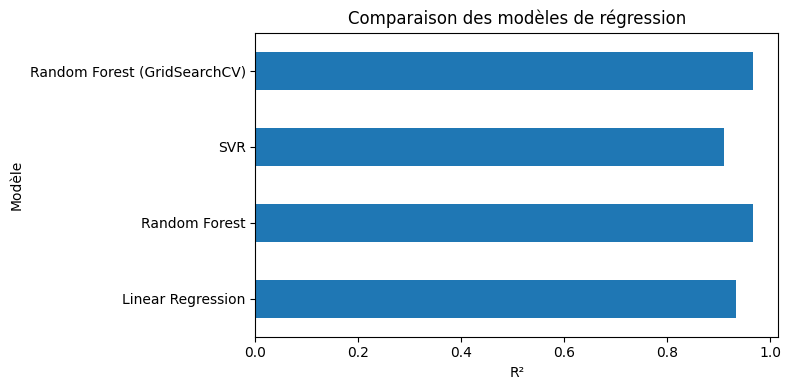

In [21]:
resultats_regression=pd.DataFrame(res_reg,index=['R2','RMSE','MAE']).T.round(4).reset_index().rename(columns={'index':'Modèle'})
resultats_classification=pd.DataFrame(res_clf,index=['Accuracy','F1 pondéré']).T.round(4).reset_index().rename(columns={'index':'Modèle'})

display(resultats_regression)
display(resultats_classification)

resultats_regression.to_csv('results/resultats_regression.csv',index=False)
resultats_classification.to_csv('results/resultats_classification.csv',index=False)
open('results/resultats_regression.md','w',encoding='utf-8').write(resultats_regression.to_markdown(index=False))
open('results/resultats_classification.md','w',encoding='utf-8').write(resultats_classification.to_markdown(index=False))

# Graphe comparatif R2 (régression)
resultats_regression.set_index('Modèle')['R2'].plot(kind='barh',figsize=(8,4))
plt.xlabel('R²'); plt.title('Comparaison des modèles de régression')
plt.tight_layout()
plt.savefig('images/12_comparaison_regression.png',dpi=150,bbox_inches='tight')
plt.show()